# **Task 01-Data Preparation and Feature Engineering**

1.1 Ticker selection and data acquisition

In [5]:
%pip install -q yfinance lxml

In [6]:
import pandas as pd
import numpy as np
import yfinance as yf
from datetime import datetime, timezone
from google.colab import drive
from pathlib import Path

In [7]:
from pathlib import Path

# Save coursework files directly in Colab
folder = Path("/content/CRM_CWK1_Data")
folder.mkdir(parents=True, exist_ok=True)

print("Data folder:", folder)

Data folder: /content/CRM_CWK1_Data


In [8]:
# Get S&P 500 tickers from Wikipedia
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
sp500 = pd.read_html(
    url, storage_options={"User-Agent": "Mozilla/5.0"}
)[0]

retrieval_date = datetime.now(timezone.utc).date().isoformat()
sp500["Retrieval_Date"] = retrieval_date
sp500["Yahoo_Ticker"] = sp500["Symbol"].str.replace(
    ".", "-", regex=False
)
tickers = sp500["Yahoo_Ticker"].tolist()

In [9]:
# Save ticker list
sp500.to_csv(folder / "sp500_constituents.csv", index=False)

In [10]:
# Download daily stock data and S&P 500 benchmark
data = yf.download(
    tickers + ["^GSPC"],
    start="2021-01-01",
    end="2025-01-01",
    interval="1d",
    auto_adjust=False,
    actions=True,
    progress=False)

ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['Q', 'VYLR', 'FDXF', 'SNDK', 'HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


In [11]:
# Check essential fields
assert not data.empty, "No data downloaded."

required = {"Close", "Adj Close", "Volume"}
fields = set(data.columns.get_level_values(0))
assert required.issubset(fields), "Required data fields are missing."

In [12]:
# Save original data
data.to_csv(
    folder / "sp500_daily_2021_2024.csv.gz",
    compression="gzip")

In [13]:

# Identify failed or empty downloads
available = (
    data["Close"].notna().any()
    & data["Adj Close"].notna().any()
    & data["Volume"].notna().any())

failed = sorted(set(tickers) - set(available[available].index))
pd.DataFrame({"Ticker": failed}).to_csv(
    folder / "download_failures.csv", index=False)

In [14]:
# Verify results
print("Retrieval date:", retrieval_date)
print("Requested stocks:", len(tickers))
print("Stocks with data:", len(tickers) - len(failed))
print("First date:", data.index.min())
print("Last date:", data.index.max())
print("Data fields:", sorted(fields))
print("S&P 500 benchmark available:", bool(available.get("^GSPC", False)))
print("Failed downloads:", failed)
print("yfinance version:", yf.__version__)

Retrieval date: 2026-11-22
Requested stocks: 503
Stocks with data: 498
First date: 2021-01-04 00:00:00
Last date: 2024-12-31 00:00:00
Data fields: ['Adj Close', 'Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']
S&P 500 benchmark available: True
Failed downloads: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']
yfinance version: 0.2.66


In [15]:
display(data["Close"].iloc[:5, :5])

Ticker,A,AAPL,ABBV,ABNB,ABT
Date,,,,,
2021-01-04,118.639999,129.410004,105.410004,139.149994,109.110001
2021-01-05,119.610001,131.009995,106.500000,148.300003,110.459999
2021-01-06,122.889999,126.599998,105.580002,142.770004,110.230003
2021-01-07,126.160004,130.919998,106.709999,151.270004,111.300003
2021-01-08,127.059998,132.050003,107.269997,149.770004,111.610001


1.2 Data Validation and Alignment

In [16]:
# Check duplicate dates
duplicates = data.index.duplicated().sum()
print("Duplicate dates:", duplicates)


if duplicates:
    raise ValueError("Duplicate dates need investigation.")

Duplicate dates: 0


In [17]:
# Match shares to benchmark trading dates
market_days = data["Adj Close"]["^GSPC"].dropna().index

close = data["Close"].reindex(index=market_days, columns=tickers)
adj = data["Adj Close"].reindex(index=market_days, columns=tickers)
volume = data["Volume"].reindex(index=market_days, columns=tickers)

In [18]:
# Check data quality without filling missing values
valid = close.gt(0) & adj.gt(0) & volume.gt(0)

checks = pd.DataFrame(index=tickers)
checks["Valid_days"] = valid.sum()
checks["Missing_days"] = (
    close.isna() | adj.isna() | volume.isna()
).sum()
checks["Bad_prices"] = (close.le(0) | adj.le(0)).sum()
checks["Bad_volume"] = volume.le(0).sum()

In [19]:
# Check unequal histories
checks["First_date"] = adj.where(valid).apply(pd.Series.first_valid_index)
checks["Last_date"] = adj.where(valid).apply(pd.Series.last_valid_index)

In [20]:
# Check recorded corporate actions
for field in ["Dividends", "Stock Splits"]:
    if field in data.columns.get_level_values(0):
        checks[field.replace(" ", "_")] = (
            data[field]
            .reindex(index=market_days, columns=tickers)
            .fillna(0).ne(0).sum()
        )

print("Benchmark trading days:", len(market_days))
print("Shares with missing data:", (checks["Missing_days"] > 0).sum())
print("Shares with bad prices:", (checks["Bad_prices"] > 0).sum())
print("Shares with bad volume:", (checks["Bad_volume"] > 0).sum())

Benchmark trading days: 1005
Shares with missing data: 15
Shares with bad prices: 0
Shares with bad volume: 2


In [21]:
display(checks.sort_values("Missing_days", ascending=False).head(15))

,Valid_days,Missing_days,Bad_prices,Bad_volume,First_date,Last_date,Dividends,Stock_Splits
HONA,0,1005,0,0,NaT,NaT,0,0
FDXF,0,1005,0,0,NaT,NaT,0,0
Q,0,1005,0,0,NaT,NaT,0,0
SNDK,0,1005,0,0,NaT,NaT,0,0
VYLR,0,1005,0,0,NaT,NaT,0,0
GEV,193,812,0,0,2024-03-27,2024-12-31,1,0
SOLV,194,811,0,0,2024-03-26,2024-12-31,0,0
RDDT,197,808,0,0,2024-03-21,2024-12-31,0,0
VLTO,313,692,0,0,2023-10-04,2024-12-31,5,0
GEHC,513,492,0,0,2022-12-15,2024-12-31,7,0


In [22]:

# Weekly alignment using adjusted closing prices

weekly_prices = (
    adj.where(adj.gt(0) & close.gt(0))
    .resample("W-FRI").last()
    .loc["2021-01-08":"2024-12-27"])

market_weekly_prices = (
    data["Adj Close"]["^GSPC"]
    .reindex(market_days)
    .resample("W-FRI").last()
    .reindex(weekly_prices.index))

weekly_returns = weekly_prices.pct_change(fill_method=None)
market_weekly_returns = market_weekly_prices.pct_change(fill_method=None)


In [23]:
# Count weeks with matching valid returns
checks["Aligned_weeks"] = (
    weekly_returns.notna()
    .mul(market_weekly_returns.notna(), axis=0)
    .sum())

In [24]:
# Review history coverage
checks["Coverage_pct"] = (valid.mean() * 100).round(1)
checks["Last80_valid"] = valid.tail(80).all()

print("Weekly dates aligned:",
      weekly_returns.index.equals(market_weekly_returns.index))

print("Weekly date range:",
      weekly_returns.index.min(),
      "to", weekly_returns.index.max())

Weekly dates aligned: True
Weekly date range: 2021-01-08 00:00:00 to 2024-12-27 00:00:00


In [25]:
display(checks[["Coverage_pct", "Aligned_weeks", "Last80_valid"]].describe())

,Coverage_pct,Aligned_weeks
count,503.000000,503.000000
mean,98.088270,203.226640
std,12.432668,25.492916
min,0.000000,0.000000
25%,100.000000,207.000000
50%,100.000000,207.000000
75%,100.000000,207.000000
max,100.000000,207.000000


In [26]:
# Save validation evidence
checks.to_csv(folder / "validation_results.csv")

1.3 Weekly return and weekly beta

1.3.1 Mean weekly return & 1.3.2 Weekly beta

In [27]:
results = []
for ticker in tickers:
    # Align stock and benchmark weekly returns
    paired = pd.concat([
        weekly_returns[ticker].rename("Stock"),
        market_weekly_returns.rename("Market")
    ], axis=1).replace([np.inf, -np.inf], np.nan).dropna()

    # Mean weekly return
    mean_return = paired["Stock"].mean()

    # Weekly beta
    beta = np.nan
    market_variance = paired["Market"].var()

    if len(paired) >= 52 and market_variance > 0:
        beta = paired["Stock"].cov(paired["Market"]) / market_variance

    results.append({
        "Ticker": ticker,
        "Mean_Weekly_Return": mean_return,
        "Weekly_Beta": beta,
        "Aligned_Weeks": len(paired)
    })

features = pd.DataFrame(results).set_index("Ticker")

In [28]:
# Display and save results
display(features.head(10))

print("Maximum aligned weeks:", features["Aligned_Weeks"].max())
print("Stocks with valid beta:", features["Weekly_Beta"].notna().sum())

features.to_csv(folder / "weekly_return_beta_features.csv")
weekly_returns.to_csv(folder / "weekly_returns.csv")
market_weekly_returns.to_csv(folder / "benchmark_weekly_returns.csv")


,Mean_Weekly_Return,Weekly_Beta,Aligned_Weeks
Ticker,,,
MMM,0.001142,0.869079,207
AOS,0.001991,1.042804,207
ABT,0.000971,0.583543,207
ABBV,0.003749,0.425366,207
ACN,0.002376,1.143300,207
ADBE,0.000990,1.553525,207
AMD,0.003624,1.877622,207
AES,-0.001420,1.143912,207
AFL,0.005004,0.707197,207


Maximum aligned weeks: 207
Stocks with valid beta: 495


In [29]:

# Independently verify beta for AAPL

paired = pd.concat([
    weekly_returns["AAPL"],
    market_weekly_returns
], axis=1).dropna()

# Regression slope is another way to calculate beta
beta_check = np.polyfit(paired.iloc[:, 1], paired.iloc[:, 0], 1)[0]

print("Original beta:", features.loc["AAPL", "Weekly_Beta"])
print("Verified beta:", beta_check)
print("Aligned weeks:", len(paired))

assert np.isclose(
    features.loc["AAPL", "Weekly_Beta"],
    beta_check
)

Original beta: 1.1748360344304585
Verified beta: 1.1748360344304585
Aligned weeks: 207


1.4 Adapted RFM Calculations

In [30]:
#Identify unusually high-volume days
observation_date = pd.Timestamp("2024-12-31")

In [31]:
# Use valid trading volume
aapl_volume = volume["AAPL"].where(volume["AAPL"] > 0)

In [32]:
# Mean of the previous 20 trading sessions
previous_20_avg = aapl_volume.shift(1).rolling(
    20, min_periods=20
).mean()

In [33]:
# Flag unusually high-volume days
high_volume = aapl_volume > (2 * previous_20_avg)

In [34]:
# Inspect the last five sessions
display(pd.DataFrame({
    "Volume": aapl_volume,
    "Previous_20_Avg": previous_20_avg,
    "High_Volume": high_volume
}).loc[:observation_date].tail(5))


,Volume,Previous_20_Avg,High_Volume
Date,,,
2024-12-24,23234700,50408480.0,False
2024-12-26,27237100,47062575.0,False
2024-12-27,42355300,46125120.0,False
2024-12-30,35557500,46567965.0,False
2024-12-31,39480700,46921770.0,False


1.4.1 Recency

In [35]:
# Find all qualifying high-volume event dates
event_dates = high_volume.loc[:observation_date]
event_dates = event_dates.index[event_dates]

if len(event_dates) > 0:
    last_event = event_dates[-1]
    recency = (observation_date - last_event).days

    print("Last high-volume event:", last_event.date())
    print("Event volume:", aapl_volume.loc[last_event])
    print("Previous 20-session average:", previous_20_avg.loc[last_event])
    print("Recency (calendar days):", recency)

else:
    recency = np.nan
    print("No qualifying event found. Recency:", recency)

Last high-volume event: 2024-12-20
Event volume: 147495300
Previous 20-session average: 45004605.0
Recency (calendar days): 11


1.4.2 Frequency

In [36]:
# Select the latest 60 trading sessions
last_60_events = high_volume.loc[:observation_date].tail(60)

# Count qualifying high-volume days
frequency = int(last_60_events.sum())

print("Window start:", last_60_events.index[0].date())
print("Window end:", last_60_events.index[-1].date())
print("Trading sessions:", len(last_60_events))
print("Frequency:", frequency)

# Display qualifying event dates
display(last_60_events[last_60_events])

Window start: 2024-10-07
Window end: 2024-12-31
Trading sessions: 60
Frequency: 2


,AAPL
Date,
2024-11-25,True
2024-12-20,True


1.4.3 Monetary

In [37]:
# Select the latest 60 trading sessions
last_60 = pd.DataFrame({
    "Close": close["AAPL"],
    "Volume": volume["AAPL"]
}).loc[:observation_date].tail(60)

In [38]:
# Validate the window
assert len(last_60) == 60
assert (last_60["Close"] > 0).all()
assert (last_60["Volume"] > 0).all()
assert last_60.index.equals(last_60_events.index)

In [39]:
# Calculate approximate daily traded value
last_60["Daily_Traded_Value"] = (
    last_60["Close"] * last_60["Volume"])

In [40]:
# Calculate Monetary
monetary = last_60["Daily_Traded_Value"].sum()

print("Window start:", last_60.index[0].date())
print("Window end:", last_60.index[-1].date())
print("Trading sessions:", len(last_60))
print(f"Monetary (USD): ${monetary:,.2f}")

Window start: 2024-10-07
Window end: 2024-12-31
Trading sessions: 60
Monetary (USD): $623,303,377,706.58


In [41]:

display(last_60.tail(5))

,Close,Volume,Daily_Traded_Value
Date,,,
2024-12-24,258.200012,23234700,5.999200e+09
2024-12-26,259.019989,27237100,7.054953e+09
2024-12-27,255.589996,42355300,1.082559e+10
2024-12-30,252.199997,35557500,8.967601e+09
2024-12-31,250.419998,39480700,9.886757e+09


In [42]:
# Identify high-volume days
clean_volume = volume.where(volume > 0)
previous_20 = clean_volume.shift(1).rolling(
    20, min_periods=20).mean()
high_volume_all = clean_volume > (2 * previous_20)

In [43]:
# Find the most recent qualifying event
last_event = high_volume_all.apply(
    lambda s: s.index[s].max() if s.any() else pd.NaT)

In [44]:
# Build the RFM features
rfm = pd.DataFrame({
    "Recency_Days": (observation_date - last_event).dt.days,
    "Frequency": high_volume_all.tail(60).sum(),
    "Monetary_USD": (close.tail(60) * volume.tail(60)).sum(
        min_count=60)
})

In [45]:
# Retain shares with complete final 80 sessions
eligible = checks.index[checks["Last80_valid"]]
rfm = rfm.loc[eligible]

In [46]:
# Review and save the results
print("Observation date:", observation_date.date())
print("Eligible shares:", len(rfm))
print("Shares with no high-volume event:",
      rfm["Recency_Days"].isna().sum())

display(rfm.head(10))
display(rfm.describe())

rfm.to_csv(folder / "rfm_features.csv")

Observation date: 2024-12-31
Eligible shares: 498
Shares with no high-volume event: 0


,Recency_Days,Frequency,Monetary_USD
MMM,11.0,4,2.599146e+10
AOS,11.0,2,4.748980e+09
ABT,11.0,1,3.523027e+10
ABBV,11.0,3,6.837054e+10
ACN,11.0,2,5.199430e+10
ADBE,18.0,3,1.030403e+11
AMD,18.0,4,3.131659e+11
AES,54.0,3,1.119578e+10
AFL,11.0,2,1.328456e+10
A,11.0,2,1.400180e+10


,Recency_Days,Frequency,Monetary_USD
count,498.000000,498.000000,4.980000e+02
mean,20.510040,3.004016,3.961352e+10
std,21.247722,1.327614,1.278859e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.025102e+10
50%,11.000000,3.000000,1.679667e+10
75%,18.000000,4.000000,3.287502e+10
max,222.000000,8.000000,1.847697e+12


In [47]:

# Verify all-stock RFM against AAPL example

print(rfm.loc["AAPL"])

assert rfm.loc["AAPL", "Recency_Days"] == recency
assert rfm.loc["AAPL", "Frequency"] == frequency
assert np.isclose(
    rfm.loc["AAPL", "Monetary_USD"], monetary
)

print("AAPL RFM verification passed.")


Recency_Days    1.100000e+01
Frequency       2.000000e+00
Monetary_USD    6.233034e+11
Name: AAPL, dtype: float64
AAPL RFM verification passed.


1.5 Metric interpretation and supporting evidence

In [48]:
# 1.5 Inclusion and exclusion log

exclusion_log = pd.DataFrame(index=tickers)
exclusion_log["Reason"] = "Included"

In [49]:
# No downloaded history
exclusion_log.loc[
    checks["Valid_days"] == 0, "Reason"
] = "No downloaded data"

In [50]:
# Insufficient recent history
exclusion_log.loc[
    (exclusion_log["Reason"] == "Included") &
    (~checks["Last80_valid"]), "Reason"
] = "Incomplete final 80 sessions"

In [51]:
# Insufficient weekly observations for beta
exclusion_log.loc[
    (exclusion_log["Reason"] == "Included") &
    (features["Weekly_Beta"].isna()), "Reason"
] = "Insufficient beta history"

In [52]:
# Missing RFM features
exclusion_log.loc[
    (exclusion_log["Reason"] == "Included") &
    (rfm["Recency_Days"].reindex(tickers).isna()), "Reason"
] = "No qualifying high-volume event"

In [53]:
exclusion_log.loc[
    (exclusion_log["Reason"] == "Included") &
    (rfm["Monetary_USD"].reindex(tickers).isna()), "Reason"
] = "Incomplete Monetary data"

In [54]:
# Common shares for clustering
common_tickers = exclusion_log.index[
    exclusion_log["Reason"] == "Included"
]

print("Inclusion and exclusion summary:")
print(exclusion_log["Reason"].value_counts())

print("\nExcluded shares:")
display(exclusion_log[exclusion_log["Reason"] != "Included"])

print("Common shares for clustering:", len(common_tickers))

exclusion_log.to_csv(folder / "inclusion_exclusion_log.csv")


Inclusion and exclusion summary:
Reason
Included                     495
No downloaded data             5
Insufficient beta history      3
Name: count, dtype: int64

Excluded shares:


,Reason
FDXF,No downloaded data
GEV,Insufficient beta history
HONA,No downloaded data
Q,No downloaded data
RDDT,Insufficient beta history
SNDK,No downloaded data
SOLV,Insufficient beta history
VYLR,No downloaded data


Common shares for clustering: 495


# **Task 2 -Stock Segmentation and Sensitivity Analysis**

2.1 Feature preparation

In [55]:
from sklearn.preprocessing import StandardScaler

# Risk and return features
risk_return = features.loc[
    common_tickers,
    ["Mean_Weekly_Return", "Weekly_Beta"]
].copy()

# RFM features
rfm_original = rfm.loc[
    common_tickers,
    ["Recency_Days", "Frequency", "Monetary_USD"]
].copy()

# Check common stocks and valid features
assert risk_return.index.equals(rfm_original.index)
assert np.isfinite(risk_return.to_numpy()).all()
assert np.isfinite(rfm_original.to_numpy()).all()
assert (rfm_original["Monetary_USD"] >= 0).all()

# Log-transform Monetary
rfm_prepared = rfm_original[["Recency_Days", "Frequency"]].copy()
rfm_prepared["log1p_Monetary"] = np.log1p(
    rfm_original["Monetary_USD"]
)

# Standardise the two matrices separately
risk_scaled = pd.DataFrame(
    StandardScaler().fit_transform(risk_return),
    index=risk_return.index,
    columns=risk_return.columns
)

rfm_scaled = pd.DataFrame(
    StandardScaler().fit_transform(rfm_prepared),
    index=rfm_prepared.index,
    columns=rfm_prepared.columns
)

print("Risk/Return shape:", risk_scaled.shape)
print("RFM shape:", rfm_scaled.shape)
print("Same stocks:", risk_scaled.index.equals(rfm_scaled.index))

display(risk_scaled.head())
display(rfm_scaled.head())


Risk/Return shape: (495, 2)
RFM shape: (495, 3)
Same stocks: True


,Mean_Weekly_Return,Weekly_Beta
MMM,-0.654507,-0.268976
AOS,-0.343155,0.144171
ABT,-0.717325,-0.948027
ABBV,0.302346,-1.324198
ACN,-0.201566,0.383167


,Recency_Days,Frequency,log1p_Monetary
MMM,-0.44758,0.753433,0.308634
AOS,-0.44758,-0.753433,-1.491293
ABT,-0.44758,-1.506865,0.630680
ABBV,-0.44758,0.000000,1.332757
ACN,-0.44758,-0.753433,1.042827


In [56]:
# Check skewness and IQR outliers

def diagnostics(df):
    q1 = df.quantile(0.25)
    q3 = df.quantile(0.75)
    iqr = q3 - q1

    outliers = (
        (df < q1 - 1.5 * iqr) |
        (df > q3 + 1.5 * iqr)
    ).sum()

    return pd.DataFrame({
        "Skewness": df.skew(),
        "IQR_Outliers": outliers
    }).round(3)

print("Risk/Return diagnostics:")
display(diagnostics(risk_return))

print("Original RFM diagnostics:")
display(diagnostics(rfm_original))

print("RFM after log1p Monetary:")
display(diagnostics(rfm_prepared))

Risk/Return diagnostics:


,Skewness,IQR_Outliers
Mean_Weekly_Return,0.969,17
Weekly_Beta,1.252,12


Original RFM diagnostics:


,Skewness,IQR_Outliers
Recency_Days,3.599,97
Frequency,0.411,2
Monetary_USD,11.707,47


RFM after log1p Monetary:


,Skewness,IQR_Outliers
Recency_Days,3.599,97
Frequency,0.411,2
log1p_Monetary,1.070,13


In [57]:

# Four exploratory baseline clustering solutions

from sklearn.cluster import AgglomerativeClustering, KMeans

baseline_k = 3  # Temporary choice for exploration

baseline = pd.DataFrame(index=common_tickers)

baseline["Risk_Ward"] = AgglomerativeClustering(
    n_clusters=baseline_k,
    linkage="ward"
).fit_predict(risk_scaled)

baseline["Risk_KMeans"] = KMeans(
    n_clusters=baseline_k,
    random_state=42,
    n_init=20
).fit_predict(risk_scaled)

baseline["RFM_Ward"] = AgglomerativeClustering(
    n_clusters=baseline_k,
    linkage="ward"
).fit_predict(rfm_scaled)

baseline["RFM_KMeans"] = KMeans(
    n_clusters=baseline_k,
    random_state=42,
    n_init=20
).fit_predict(rfm_scaled)

display(baseline.head())

for column in baseline.columns:
    print("\n", column)
    print(baseline[column].value_counts().sort_index())

baseline.to_csv(folder / "baseline_cluster_assignments.csv")


,Risk_Ward,Risk_KMeans,RFM_Ward,RFM_KMeans
MMM,2,1,2,0
AOS,2,1,0,0
ABT,1,0,2,1
ABBV,1,0,2,1
ACN,2,1,2,1



 Risk_Ward
Risk_Ward
0     95
1    212
2    188
Name: count, dtype: int64

 Risk_KMeans
Risk_KMeans
0    207
1    167
2    121
Name: count, dtype: int64

 RFM_Ward
RFM_Ward
0    254
1     94
2    147
Name: count, dtype: int64

 RFM_KMeans
RFM_KMeans
0    275
1    155
2     65
Name: count, dtype: int64


2.2 Agglomerative clustering

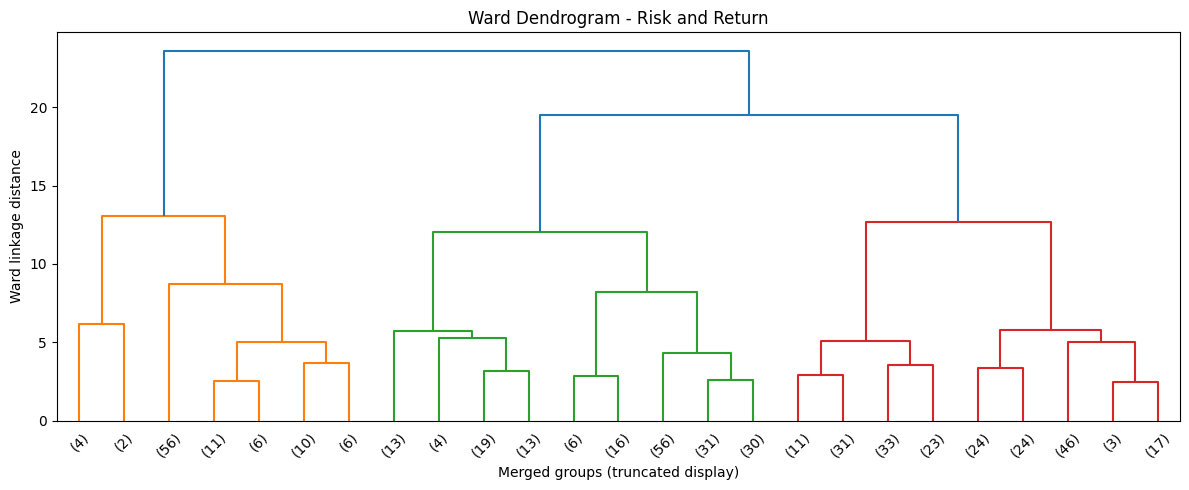

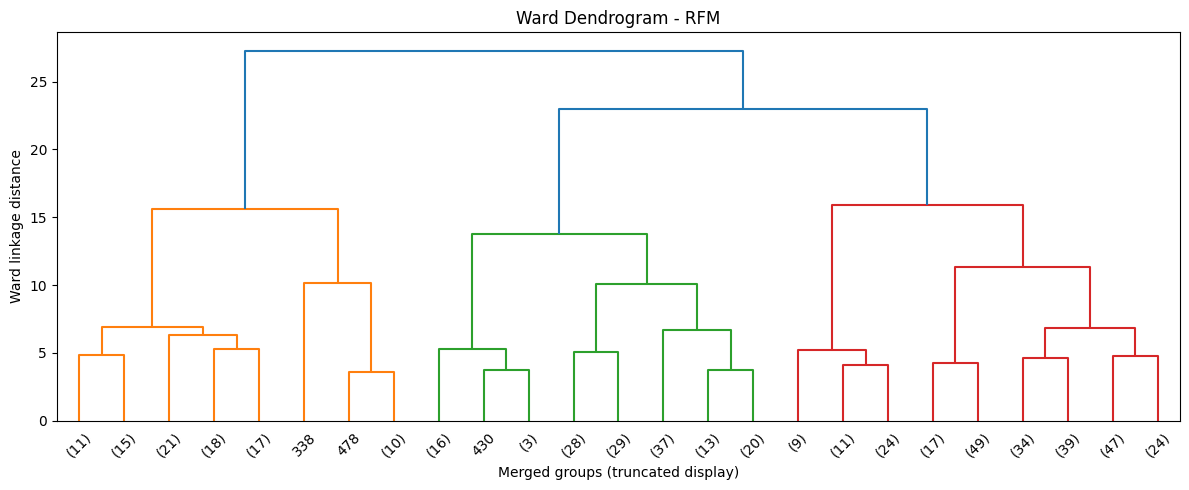

In [58]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree

# Ward linkage with Euclidean distance
ward_risk = linkage(
    risk_scaled, method="ward", metric="euclidean"
)

ward_rfm = linkage(
    rfm_scaled, method="ward", metric="euclidean"
)

# Plot two dendrograms
for name, tree, filename in [
    ("Risk and Return", ward_risk, "ward_risk_dendrogram.png"),
    ("RFM", ward_rfm, "ward_rfm_dendrogram.png")
]:
    plt.figure(figsize=(12, 5))

    dendrogram(
        tree,
        truncate_mode="lastp",
        p=25,
        show_leaf_counts=True
    )

    plt.title("Ward Dendrogram - " + name)
    plt.xlabel("Merged groups (truncated display)")
    plt.ylabel("Ward linkage distance")
    plt.tight_layout()
    plt.savefig(folder / filename, dpi=150)
    plt.show()


In [59]:

# Evaluate Ward clustering for k = 2 to 8

from sklearn.metrics import silhouette_score

ward_results = []

for name, X, tree in [
    ("Risk/Return", risk_scaled, ward_risk),
    ("RFM", rfm_scaled, ward_rfm)
]:
    for k in range(2, 9):

        # Create k clusters from the Ward tree
        labels = cut_tree(tree, n_clusters=k).ravel()

        # Silhouette score
        score = silhouette_score(X, labels)

        # Cluster sizes
        sizes = pd.Series(labels).value_counts()

        ward_results.append({
            "Matrix": name,
            "k": k,
            "Silhouette": score,
            "Smallest_Cluster": sizes.min(),
            "Largest_Cluster": sizes.max(),
            "Cluster_Sizes": str(
                sizes.sort_index().tolist()
            )
        })

ward_results = pd.DataFrame(ward_results)

display(ward_results.round(3))

ward_results.to_csv(
    folder / "ward_k_evaluation.csv",
    index=False
)


,Matrix,k,Silhouette,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,Risk/Return,2,0.350,95,400,"[400, 95]"
1,Risk/Return,3,0.284,95,212,"[188, 212, 95]"
2,Risk/Return,4,0.291,6,212,"[188, 212, 89, 6]"
3,Risk/Return,5,0.272,6,188,"[188, 114, 98, 89, 6]"
4,Risk/Return,6,0.301,6,139,"[139, 114, 98, 49, 89, 6]"
5,Risk/Return,7,0.296,6,139,"[139, 114, 98, 49, 56, 33, 6]"
6,Risk/Return,8,0.313,6,117,"[117, 114, 98, 49, 22, 56, 33, 6]"
7,RFM,2,0.358,94,401,"[401, 94]"
8,RFM,3,0.308,94,254,"[147, 254, 94]"
9,RFM,4,0.292,44,210,"[147, 210, 94, 44]"


In [60]:

# Compare profiles for the top two silhouette candidates

for name, original, tree in [
    ("Risk/Return", risk_return, ward_risk),
    ("RFM", rfm_original, ward_rfm)
]:
    top_k = (
        ward_results[ward_results["Matrix"] == name]
        .nlargest(2, "Silhouette")["k"]
    )

    for k in top_k:
        profile_data = original.copy()
        profile_data["Cluster"] = cut_tree(
            tree, n_clusters=int(k)
        ).ravel()

        # Use readable units
        if name == "Risk/Return":
            profile_data["Mean_Weekly_Return"] *= 100
        else:
            profile_data["Monetary_USD"] /= 1e9

        profile = profile_data.groupby("Cluster").mean()
        profile.insert(
            0, "Stocks",
            profile_data.groupby("Cluster").size()
        )

        print("\n", name, "- k =", k)
        print("Return in %, Monetary in USD billions")
        display(profile.round(3))



 Risk/Return - k = 2
Return in %, Monetary in USD billions


,Stocks,Mean_Weekly_Return,Weekly_Beta
Cluster,,,
0,400,0.208,0.901
1,95,0.648,1.326



 Risk/Return - k = 8
Return in %, Monetary in USD billions


,Stocks,Mean_Weekly_Return,Weekly_Beta
Cluster,,,
0,117,0.200,1.028
1,114,0.101,0.574
2,98,0.427,0.708
3,49,0.206,1.632
4,22,-0.161,1.140
5,56,0.471,1.211
6,33,0.834,1.303
7,6,1.267,2.521



 RFM - k = 2
Return in %, Monetary in USD billions


,Stocks,Recency_Days,Frequency,Monetary_USD
Cluster,,,,
0,401,12.322,3.217,38.224
1,94,55.532,2.074,45.650



 RFM - k = 6
Return in %, Monetary in USD billions


,Stocks,Recency_Days,Frequency,Monetary_USD
Cluster,,,,
0,127,11.654,2.709,45.005
1,210,11.138,2.948,11.133
2,20,19.350,4.550,331.130
3,82,47.439,2.354,27.308
4,12,110.833,0.167,170.986
5,44,16.705,5.364,14.816


 2.3 K means clustering

In [61]:

# 2.3 K-means clustering - compare k = 2 to 8

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans_results = []

for name, X in [
    ("Risk/Return", risk_scaled),
    ("RFM", rfm_scaled)
]:
    for k in range(2, 9):

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        labels = model.fit_predict(X)
        sizes = pd.Series(labels).value_counts().sort_index()

        kmeans_results.append({
            "Matrix": name,
            "k": k,
            "Silhouette": silhouette_score(X, labels),
            "Inertia": model.inertia_,
            "Smallest_Cluster": sizes.min(),
            "Largest_Cluster": sizes.max(),
            "Cluster_Sizes": str(sizes.tolist())
        })

kmeans_results = pd.DataFrame(kmeans_results)

display(kmeans_results.round(3))

kmeans_results.to_csv(
    folder / "kmeans_k_evaluation.csv",
    index=False
)


,Matrix,k,Silhouette,Inertia,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,Risk/Return,2,0.390,631.092,146,349,"[349, 146]"
1,Risk/Return,3,0.319,477.821,121,207,"[207, 167, 121]"
2,Risk/Return,4,0.323,376.840,40,168,"[168, 162, 125, 40]"
3,Risk/Return,5,0.337,315.680,23,156,"[129, 55, 23, 156, 132]"
4,Risk/Return,6,0.338,262.867,7,162,"[106, 53, 162, 127, 40, 7]"
5,Risk/Return,7,0.332,227.096,7,144,"[84, 51, 92, 77, 40, 7, 144]"
6,Risk/Return,8,0.352,194.859,7,138,"[138, 40, 77, 80, 7, 30, 79, 44]"
7,RFM,2,0.419,1087.230,72,423,"[423, 72]"
8,RFM,3,0.325,813.713,65,275,"[275, 155, 65]"
9,RFM,4,0.342,620.937,62,215,"[124, 62, 215, 94]"


In [62]:

# Profiles for the two best silhouette candidates

for name, X, original in [
    ("Risk/Return", risk_scaled, risk_return),
    ("RFM", rfm_scaled, rfm_original)
]:

    top_k = (
        kmeans_results[kmeans_results["Matrix"] == name]
        .nlargest(2, "Silhouette")["k"]
    )

    for k in top_k:

        model = KMeans(
            n_clusters=int(k),
            random_state=42,
            n_init=20
        )

        profile_data = original.copy()
        profile_data["Cluster"] = model.fit_predict(X)

        # Display original units
        if name == "Risk/Return":
            profile_data["Mean_Weekly_Return"] *= 100
        else:
            profile_data["Monetary_USD"] /= 1e9

        profile = profile_data.groupby("Cluster").mean()
        profile.insert(
            0, "Stocks",
            profile_data.groupby("Cluster").size()
        )

        print("\n", name, "- k =", k)
        print("Return in %, Monetary in USD billions")
        display(profile.round(3))



 Risk/Return - k = 2
Return in %, Monetary in USD billions


,Stocks,Mean_Weekly_Return,Weekly_Beta
Cluster,,,
0,349,0.187,0.818
1,146,0.546,1.374



 Risk/Return - k = 8
Return in %, Monetary in USD billions


,Stocks,Mean_Weekly_Return,Weekly_Beta
Cluster,,,
0,138,0.192,0.968
1,40,-0.096,1.271
2,77,0.402,0.620
3,80,0.079,0.497
4,7,1.224,2.447
5,30,0.845,1.248
6,79,0.471,1.110
7,44,0.312,1.638



 RFM - k = 2
Return in %, Monetary in USD billions


,Stocks,Recency_Days,Frequency,Monetary_USD
Cluster,,,,
0,423,13.385,3.196,32.661
1,72,62.486,1.847,80.601



 RFM - k = 5
Return in %, Monetary in USD billions


,Stocks,Recency_Days,Frequency,Monetary_USD
Cluster,,,,
0,124,13.895,4.548,14.964
1,11,113.909,0.091,184.004
2,89,14.584,3.270,121.536
3,201,11.627,2.358,15.115
4,70,50.714,2.214,26.924


2.4 Cluster profiles and algorithm comparison

In [63]:

from scipy.cluster.hierarchy import cut_tree
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Confirm both matrices use the same stocks
assert risk_scaled.index.equals(rfm_scaled.index)

# Final cluster assignments (k = 2)
cluster_labels = pd.DataFrame(index=risk_scaled.index)

cluster_labels["Ward_Risk"] = cut_tree(
    ward_risk, n_clusters=2
).ravel()

cluster_labels["KMeans_Risk"] = KMeans(
    n_clusters=2, random_state=42, n_init=20
).fit_predict(risk_scaled)

cluster_labels["Ward_RFM"] = cut_tree(
    ward_rfm, n_clusters=2
).ravel()

cluster_labels["KMeans_RFM"] = KMeans(
    n_clusters=2, random_state=42, n_init=20
).fit_predict(rfm_scaled)

print("Stocks compared:", len(cluster_labels))

# Measure how similar the group assignments are
comparison = pd.DataFrame({
    "Matrix": ["Risk/Return", "RFM"],
    "Ward_vs_KMeans_ARI": [
        adjusted_rand_score(
            cluster_labels["Ward_Risk"],
            cluster_labels["KMeans_Risk"]
        ),
        adjusted_rand_score(
            cluster_labels["Ward_RFM"],
            cluster_labels["KMeans_RFM"]
        )
    ]
})

display(comparison.round(3))
cluster_labels.to_csv(folder / "final_cluster_labels.csv")


Stocks compared: 495


,Matrix,Ward_vs_KMeans_ARI
0,Risk/Return,0.605
1,RFM,0.753


In [64]:

# Compare cluster profiles in original units

def cluster_profile(data, labels, matrix):
    result = data.copy()
    result["Cluster"] = labels

    profile = result.groupby("Cluster").mean()
    profile.insert(
        0, "Stocks",
        result.groupby("Cluster").size()
    )

    if matrix == "Risk":
        profile["Mean_Weekly_Return"] *= 100
    else:
        profile["Monetary_USD"] /= 1e9

    return profile.round(3)

for name, original, matrix in [
    ("Ward_Risk", risk_return, "Risk"),
    ("KMeans_Risk", risk_return, "Risk"),
    ("Ward_RFM", rfm_original, "RFM"),
    ("KMeans_RFM", rfm_original, "RFM")
]:
    profile = cluster_profile(
        original, cluster_labels[name], matrix
    )

    print("\n", name)
    print("Return in %, Monetary in USD billions")
    display(profile)

    profile.to_csv(folder / f"{name}_profile.csv")



 Ward_Risk
Return in %, Monetary in USD billions


,Stocks,Mean_Weekly_Return,Weekly_Beta
Cluster,,,
0,400,0.208,0.901
1,95,0.648,1.326



 KMeans_Risk
Return in %, Monetary in USD billions


,Stocks,Mean_Weekly_Return,Weekly_Beta
Cluster,,,
0,349,0.187,0.818
1,146,0.546,1.374



 Ward_RFM
Return in %, Monetary in USD billions


,Stocks,Recency_Days,Frequency,Monetary_USD
Cluster,,,,
0,401,12.322,3.217,38.224
1,94,55.532,2.074,45.650



 KMeans_RFM
Return in %, Monetary in USD billions


,Stocks,Recency_Days,Frequency,Monetary_USD
Cluster,,,,
0,423,13.385,3.196,32.661
1,72,62.486,1.847,80.601


RFM PCA variance explained: 79.54 %


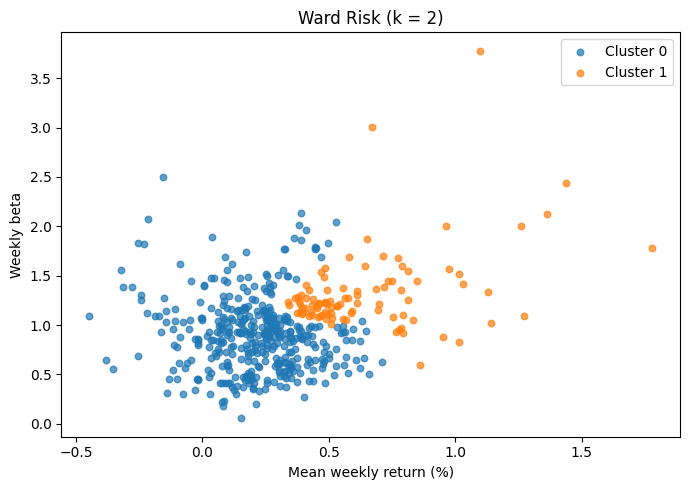

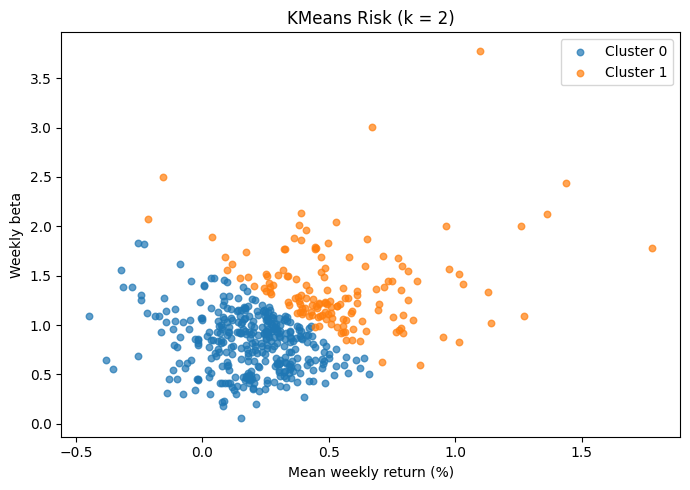

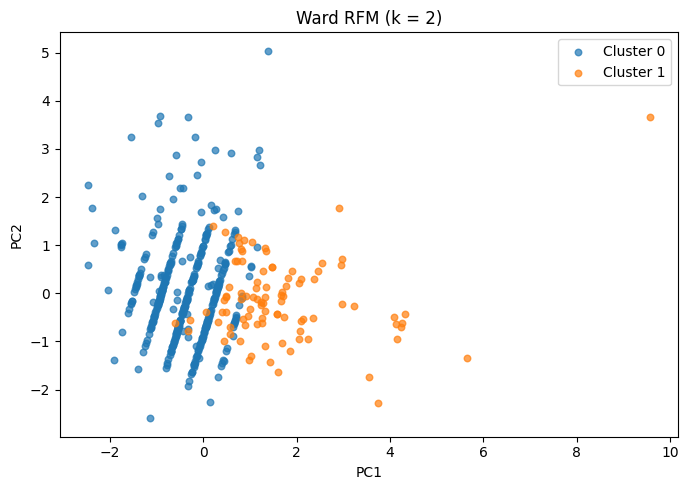

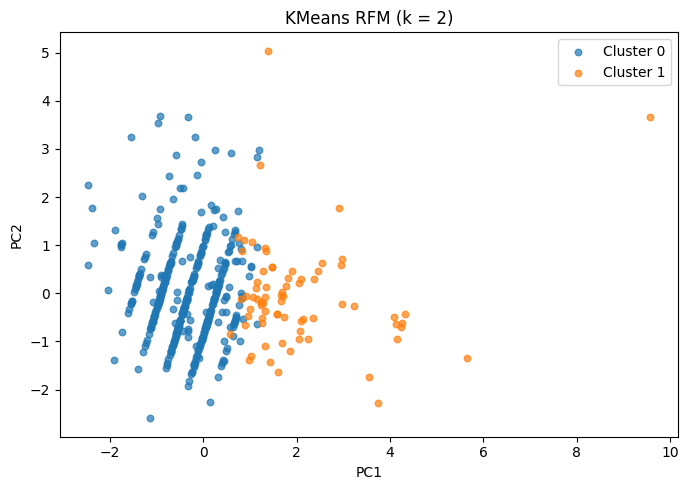

In [65]:

# 2D cluster visualisations

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Risk/Return: original units
risk_xy = pd.DataFrame({
    "Mean weekly return (%)":
        risk_return["Mean_Weekly_Return"] * 100,
    "Weekly beta": risk_return["Weekly_Beta"]
})

# RFM: reduce 3 features to 2 for plotting only
pca = PCA(n_components=2)
rfm_xy = pd.DataFrame(
    pca.fit_transform(rfm_scaled),
    index=rfm_scaled.index,
    columns=["PC1", "PC2"]
)

print(
    "RFM PCA variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# Plot Ward and K-means for each matrix
for name, xy in [
    ("Ward_Risk", risk_xy),
    ("KMeans_Risk", risk_xy),
    ("Ward_RFM", rfm_xy),
    ("KMeans_RFM", rfm_xy)
]:
    plt.figure(figsize=(7, 5))

    for cluster in sorted(cluster_labels[name].unique()):
        points = xy.loc[cluster_labels[name] == cluster]

        plt.scatter(
            points.iloc[:, 0],
            points.iloc[:, 1],
            label=f"Cluster {cluster}",
            s=22,
            alpha=0.7
        )

    plt.xlabel(xy.columns[0])
    plt.ylabel(xy.columns[1])
    plt.title(name.replace("_", " ") + " (k = 2)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(folder / f"{name}_2D.png", dpi=150)
    plt.show()

2.5 RFM Sensitivity and Correlated Inputs

2.5.1 Correlation Analysis

In [66]:

# 2.5.1 Correlation analysis

# Use original R, F and log-transformed Monetary
correlation = rfm_prepared.corr()

print("RFM correlation matrix:")
display(correlation.round(3))

correlation.to_csv(
    folder / "rfm_correlations.csv"
)

RFM correlation matrix:


,Recency_Days,Frequency,log1p_Monetary
Recency_Days,1.000,-0.341,0.164
Frequency,-0.341,1.000,0.019
log1p_Monetary,0.164,0.019,1.000


In [67]:

# 2.5.2 Remove Monetary and repeat Ward clustering

from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, cut_tree
from sklearn.metrics import adjusted_rand_score

# Keep only Recency and Frequency
rf_only = rfm_original[
    ["Recency_Days", "Frequency"]
].copy()

# Standardise the reduced matrix afresh
rf_only_scaled = pd.DataFrame(
    StandardScaler().fit_transform(rf_only),
    index=rf_only.index,
    columns=rf_only.columns
)

# Same shares and selected k = 2
assert rf_only_scaled.index.equals(
    cluster_labels.index
)

# Ward clustering without Monetary
ward_rf_tree = linkage(
    rf_only_scaled,
    method="ward",
    metric="euclidean"
)

ward_rf_labels = cut_tree(
    ward_rf_tree,
    n_clusters=2
).ravel()

# Compare with the original Ward RFM model
comparison_labels = pd.DataFrame(
    index=rf_only.index
)

comparison_labels["Ward_Full_RFM"] = (
    cluster_labels["Ward_RFM"]
)

comparison_labels["Ward_RF_Only"] = ward_rf_labels

# Adjusted Rand Index
rf_ari = adjusted_rand_score(
    comparison_labels["Ward_Full_RFM"],
    comparison_labels["Ward_RF_Only"]
)

print("Stocks compared:", len(comparison_labels))
print("Selected k: 2")
print("ARI after removing Monetary:", round(rf_ari, 3))

print("\nCluster membership comparison:")
display(pd.crosstab(
    comparison_labels["Ward_Full_RFM"],
    comparison_labels["Ward_RF_Only"]
))

comparison_labels.to_csv(
    folder / "ward_without_monetary_labels.csv"
)

Stocks compared: 495
Selected k: 2
ARI after removing Monetary: 0.953

Cluster membership comparison:


Ward_RF_Only,0,1
Ward_Full_RFM,,
0,399,2
1,3,91


In [68]:

# Compare original-unit profiles with and without Monetary

for model_name in [
    "Ward_Full_RFM",
    "Ward_RF_Only"
]:

    data_profile = rfm_original.copy()
    data_profile["Cluster"] = comparison_labels[model_name]

    profile = data_profile.groupby("Cluster").agg(
        Stocks=("Monetary_USD", "size"),
        Mean_Recency=("Recency_Days", "mean"),
        Mean_Frequency=("Frequency", "mean"),
        Mean_Monetary=("Monetary_USD", "mean"),
        Median_Monetary=("Monetary_USD", "median")
    )

    # Convert Monetary to USD billions
    profile["Mean_Monetary"] /= 1e9
    profile["Median_Monetary"] /= 1e9

    print("\n", model_name)
    print("Monetary values in USD billions")
    display(profile.round(3))

    profile.to_csv(
        folder / f"{model_name}_sensitivity_profile.csv"
    )



 Ward_Full_RFM
Monetary values in USD billions


,Stocks,Mean_Recency,Mean_Frequency,Mean_Monetary,Median_Monetary
Cluster,,,,,
0,401,12.322,3.217,38.224,15.464
1,94,55.532,2.074,45.650,20.950



 Ward_RF_Only
Monetary values in USD billions


,Stocks,Mean_Recency,Mean_Frequency,Mean_Monetary,Median_Monetary
Cluster,,,,,
0,402,12.313,3.219,37.700,15.396
1,93,56.032,2.054,47.996,21.053


3.2 Review of results and visualisation

3.2.1 Cluster profiles and sector composition

In [69]:
# Combine the original features for the same shares
all_features = risk_return.join(rfm_original)

assert all_features.index.equals(cluster_labels.index)

# Convert to readable units
all_features["Mean_Weekly_Return"] *= 100
all_features["Monetary_USD"] /= 1e9

profiles = []

for model in [
    "Ward_Risk", "Ward_RFM",
    "KMeans_Risk", "KMeans_RFM"
]:
    df = all_features.copy()
    df["Cluster"] = cluster_labels[model]

    result = df.groupby("Cluster").agg(
        Stocks=("Weekly_Beta", "size"),
        Return_Percent=("Mean_Weekly_Return", "mean"),
        Beta=("Weekly_Beta", "mean"),
        Recency_Days=("Recency_Days", "mean"),
        Frequency=("Frequency", "mean"),
        Monetary_Billion_USD=("Monetary_USD", "mean")
    ).reset_index()

    result.insert(0, "Model", model)
    profiles.append(result)

profile_comparison = pd.concat(
    profiles, ignore_index=True
)

print("Cluster profiles in original units:")
display(profile_comparison.round(2))

print("Ward Risk vs Ward RFM membership:")
display(pd.crosstab(
    cluster_labels["Ward_Risk"],
    cluster_labels["Ward_RFM"]
))

profile_comparison.to_csv(
    folder / "task3_2_cluster_profiles.csv",
    index=False
)


Cluster profiles in original units:


,Model,Cluster,Stocks,Return_Percent,Beta,Recency_Days,Frequency,Monetary_Billion_USD
0,Ward_Risk,0,400,0.21,0.90,19.64,2.95,30.04
1,Ward_Risk,1,95,0.65,1.33,24.27,3.21,80.05
2,Ward_RFM,0,401,0.29,0.97,12.32,3.22,38.22
3,Ward_RFM,1,94,0.31,1.02,55.53,2.07,45.65
4,KMeans_Risk,0,349,0.19,0.82,19.36,2.93,21.89
5,KMeans_Risk,1,146,0.55,1.37,23.32,3.17,82.04
6,KMeans_RFM,0,423,0.29,0.97,13.39,3.20,32.66
7,KMeans_RFM,1,72,0.33,1.03,62.49,1.85,80.60


Ward Risk vs Ward RFM membership:


Ward_RFM,0,1
Ward_Risk,,
0,327,73
1,74,21


In [70]:

# 3.2.1 Sector composition of the clusters

import matplotlib.pyplot as plt

In [71]:
# Sector information from the original Wikipedia list
sector_lookup = (
    sp500[["Yahoo_Ticker", "GICS Sector"]]
    .drop_duplicates("Yahoo_Ticker")
    .set_index("Yahoo_Ticker")["GICS Sector"]
)

sector_data = cluster_labels.copy()
sector_data["Sector"] = sector_lookup.reindex(
    sector_data.index
)

print("Stocks:", len(sector_data))
print("Missing sectors:", sector_data["Sector"].isna().sum())

assert sector_data["Sector"].notna().all()

Stocks: 495
Missing sectors: 0


In [72]:
# Calculate percentage distribution for each cluster
sector_percent = {}

for model in [
    "Ward_Risk", "Ward_RFM",
    "KMeans_Risk", "KMeans_RFM"
]:
    counts = pd.crosstab(
        sector_data[model],
        sector_data["Sector"]
    )

    percentages = (
        counts.div(counts.sum(axis=1), axis=0) * 100
    )

    sector_percent[model] = percentages

    print("\nSector composition:", model)
    display(percentages.round(1))

    percentages.to_csv(
        folder / f"sector_{model}.csv"
    )



Sector composition: Ward_Risk


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_Risk,,,,,,,,,,,
0,3.8,9.0,8.0,4.2,15.5,14.2,14.8,11.2,5.2,6.8,7.2
1,6.3,11.6,0.0,4.2,14.7,2.1,22.1,30.5,3.2,3.2,2.1



Sector composition: Ward_RFM


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RFM,,,,,,,,,,,
0,4.2,9.2,6.0,4.7,15.5,12.5,17.7,13.5,4.0,7.5,5.2
1,4.3,10.6,8.5,2.1,14.9,9.6,9.6,21.3,8.5,0.0,10.6



Sector composition: KMeans_Risk


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_Risk,,,,,,,,,,,
0,4.3,6.9,8.9,3.4,16.3,16.3,14.9,7.4,5.7,7.7,8.0
1,4.1,15.8,0.7,6.2,13.0,1.4,19.2,32.9,2.7,2.1,2.1



Sector composition: KMeans_RFM


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_RFM,,,,,,,,,,,
0,4.5,9.2,6.4,4.7,15.1,12.1,17.7,13.9,4.3,7.1,5.0
1,2.8,11.1,6.9,1.4,16.7,11.1,6.9,20.8,8.3,0.0,13.9


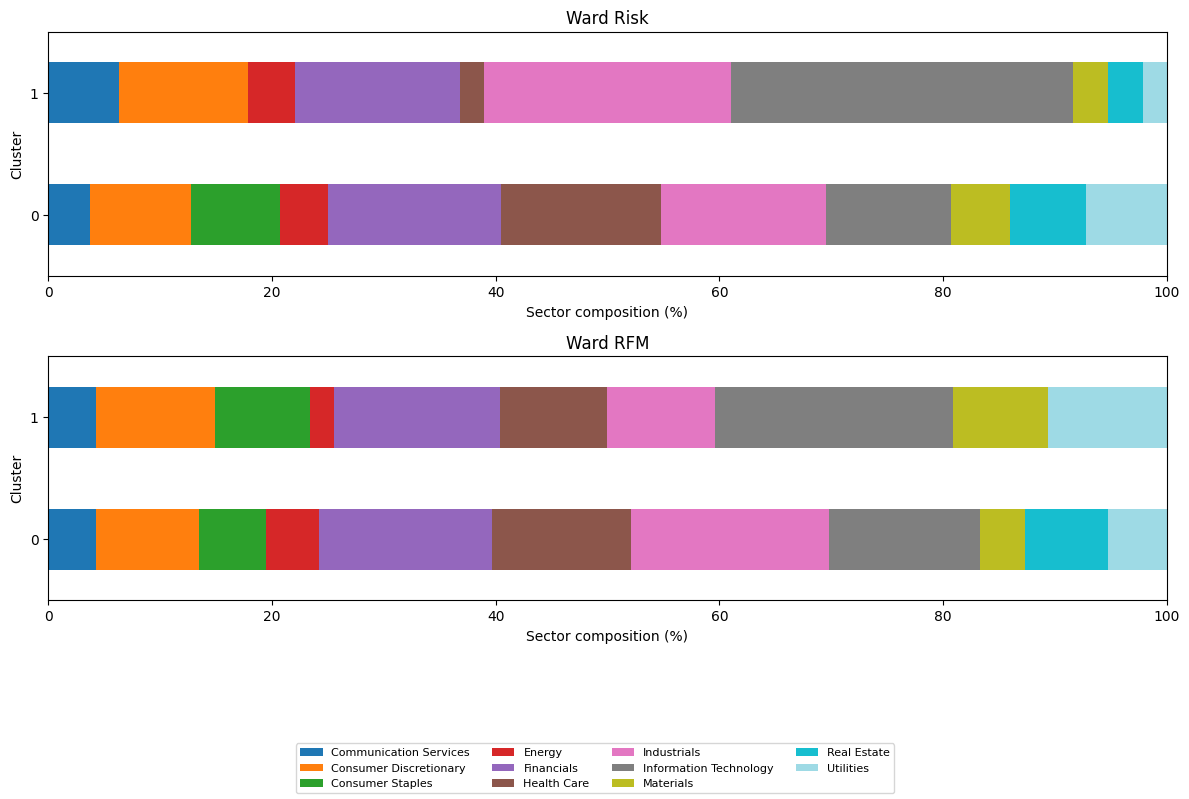

In [73]:

# Plot the two Ward solutions for the report
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

for ax, model in zip(
    axes, ["Ward_Risk", "Ward_RFM"]
):
    sector_percent[model].plot(
        kind="barh",
        stacked=True,
        ax=ax,
        colormap="tab20",
        legend=False
    )

    ax.set_title(model.replace("_", " "))
    ax.set_xlabel("Sector composition (%)")
    ax.set_ylabel("Cluster")
    ax.set_xlim(0, 100)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="lower center",
    ncol=4,
    fontsize=8
)

plt.tight_layout(rect=[0, 0.17, 1, 1])

plt.savefig(
    folder / "task3_2_sector_composition.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
